# Chapter 5 - Classification

## Learning objectives
Classification predicts a discrete target: for example, whether a medical screen is malignant, a transaction is fraudulent, or a customer will convert. This notebook implements probabilistic classification, naive Bayes, discriminant analysis, logistic regression, and evaluation with an original workflow based on the chapter's topics.

**Tools:** `GaussianNB`, LDA, logistic regression, train/test split, cross-validation, confusion matrices, ROC/AUC, precision-recall, and class weighting.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
rng = np.random.default_rng(42)
sns.set_theme(style="whitegrid", context="notebook")

## 1. Study notes: probabilities, decisions, and metrics

For classes $k=1,\ldots,K$, a classifier estimates $P(Y=k\mid X=x)$ and chooses the class with largest expected utility. In binary classification, classify positive when $\hat p=P(Y=1\mid X)$ exceeds a threshold $t$; $t=0.5$ is a convention, not a universal rule.

| Quantity | Formula | Use / caution |
|---|---|---|
| Accuracy | $(TP+TN)/(TP+TN+FP+FN)$ | Misleading when positives are rare. |
| Precision | $TP/(TP+FP)$ | Of flagged cases, how many are truly positive? |
| Recall / sensitivity | $TP/(TP+FN)$ | Of true positives, how many were found? |
| Specificity | $TN/(TN+FP)$ | Ability to reject negatives. |
| ROC-AUC | area under TPR vs FPR curve | Threshold-independent ranking measure; not a business cost. |

A confusion matrix depends on both the model and the operating threshold. Choose threshold using the cost of false positives/negatives and capacity to review alerts.

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, roc_auc_score,
                             RocCurveDisplay, precision_recall_curve, PrecisionRecallDisplay)

# Built-in dataset keeps the notebook runnable without external files.
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target  # 0=malignant, 1=benign in sklearn's source labels
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.25, stratify=y, random_state=42)
print(f"Records: {len(X)}; features: {X.shape[1]}")
print("Class proportions", y.value_counts(normalize=True).rename(index=dict(enumerate(data.target_names))).round(3))

Records: 569; features: 30
Class proportions target
benign       0.627
malignant    0.373
Name: proportion, dtype: float64


## 2. Naive Bayes and discriminant analysis

**Naive Bayes** applies Bayes' rule, $P(Y=k\mid X)\propto P(Y=k)P(X\mid Y=k)$, and assumes features are conditionally independent given class. Gaussian naive Bayes models each feature as normal within a class. It is fast and often useful, but correlated features can make its probability estimates overconfident.

**Linear discriminant analysis (LDA)** assumes class-conditional multivariate normals with a shared covariance matrix, yielding linear decision boundaries. QDA gives each class its own covariance and can express quadratic boundaries, at the cost of more parameters and data. Both require thoughtful scaling/regularization in high-dimensional settings.

In [3]:
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

models = {
    "Gaussian NB": Pipeline([("scale", StandardScaler()), ("model", GaussianNB())]),
    "LDA": Pipeline([("scale", StandardScaler()), ("model", LinearDiscriminantAnalysis())]),
    "QDA (regularized)": Pipeline([("scale", StandardScaler()), ("model", QuadraticDiscriminantAnalysis(reg_param=.05))]),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = {name: cross_val_score(model, X, y, cv=cv, scoring="roc_auc").mean() for name, model in models.items()}
pd.Series(scores, name="5-fold ROC-AUC").sort_values(ascending=False).to_frame()

,5-fold ROC-AUC
LDA,0.992879
QDA (regularized),0.991973
Gaussian NB,0.986009


## 3. Logistic regression

Logistic regression models log-odds as a linear function:

$$\log\left(\frac{p(x)}{1-p(x)}\right)=\beta_0+\beta_1x_1+\cdots+\beta_px_p,\qquad p(x)=\frac{1}{1+e^{-\eta}}.$$

It minimizes logistic (cross-entropy) loss, $-\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)]$, often with a regularization penalty. `C` is inverse regularization strength: smaller `C` means stronger shrinkage. With standardized features, $e^{\beta_j}$ is an approximate odds ratio for a one-standard-deviation feature increase, conditional on other features.

In [4]:
from sklearn.linear_model import LogisticRegression

# Scaling makes the L2 penalty comparable across differently sized features.
logistic = Pipeline([("scale", StandardScaler()),
                     ("model", LogisticRegression(C=1.0, max_iter=5000, random_state=42))])
logistic.fit(X_train, y_train)
prob_benign = logistic.predict_proba(X_test)[:, 1]
pred_benign = (prob_benign >= .5).astype(int)
print(classification_report(y_test, pred_benign, target_names=data.target_names))
print(f"Test ROC-AUC: {roc_auc_score(y_test, prob_benign):.3f}")
coef = pd.Series(logistic.named_steps["model"].coef_[0], index=X.columns)
display(pd.DataFrame({"standardized coefficient": coef, "odds ratio": np.exp(coef)}).sort_values("standardized coefficient"))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143

Test ROC-AUC: 0.998


,standardized coefficient,odds ratio
worst texture,-1.250149,0.286462
radius error,-1.070102,0.342973
worst symmetry,-0.957045,0.384026
worst concave points,-0.941888,0.389891
area error,-0.941059,0.390214
worst area,-0.925812,0.396210
worst radius,-0.917480,0.399525
worst concavity,-0.796758,0.450788
worst perimeter,-0.721168,0.486184
mean concave points,-0.676929,0.508175


## 4. Evaluation, rare classes, and threshold choice

ROC plots true-positive rate against false-positive rate across thresholds. Precision-recall is especially informative with a rare positive class because it focuses on the alerts. AUC evaluates ranking, whereas deployment needs an explicit threshold. Remedies for imbalance include collecting more positive cases, class weights, under/oversampling *only on the training data*, and cost-sensitive thresholds. Never resample before splitting because that leaks test information.

threshold=0.35: precision=0.968, recall=1.000, specificity=0.943
threshold=0.50: precision=0.989, recall=0.989, specificity=0.981
threshold=0.70: precision=0.988, recall=0.933, specificity=0.981


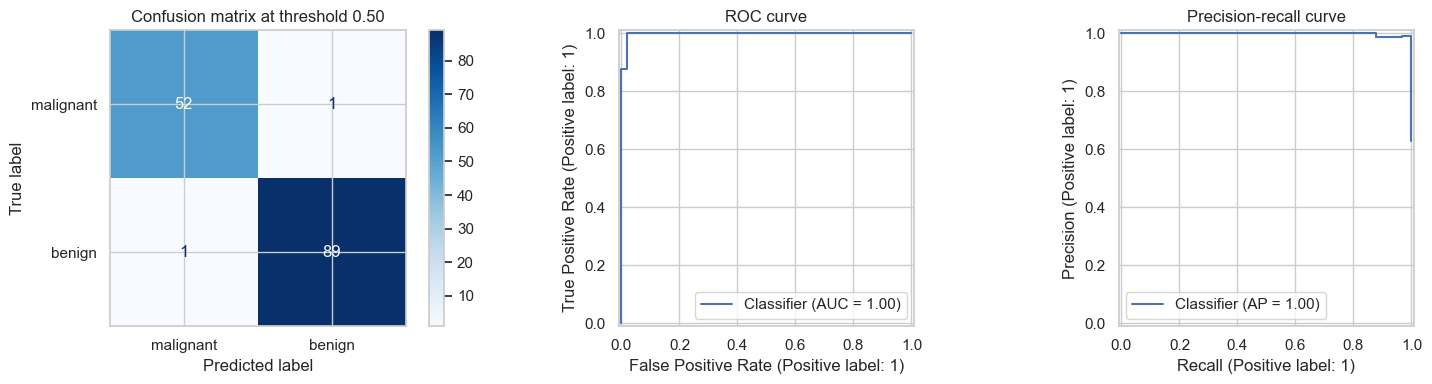

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_benign, display_labels=data.target_names, cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion matrix at threshold 0.50")
RocCurveDisplay.from_predictions(y_test, prob_benign, ax=axes[1]); axes[1].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, prob_benign, ax=axes[2]); axes[2].set_title("Precision-recall curve")
plt.tight_layout()

# A stricter threshold changes the operational trade-off, not the underlying scores.
for threshold in [.35, .50, .70]:
    predicted = (prob_benign >= threshold).astype(int)
    tn, fp, fn, tp = __import__("sklearn.metrics", fromlist=["confusion_matrix"]).confusion_matrix(y_test, predicted).ravel()
    print(f"threshold={threshold:.2f}: precision={tp/(tp+fp):.3f}, recall={tp/(tp+fn):.3f}, specificity={tn/(tn+fp):.3f}")

## Summary and key takeaways

- Separate probability estimation, threshold selection, and the business decision; a classifier is not automatically a decision rule.
- Evaluate on a held-out test set and use stratified splits for imbalanced targets.
- Compare models with metrics that match the problem; accuracy alone often hides rare-class failure.
- Scale inputs for distance- or penalty-sensitive models, and fit preprocessing only on training folds.
- Treat model coefficients and predicted probabilities as conditional, model-based quantities; inspect calibration and data shift before deployment.

**Reference:** Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists* (2nd ed.), Chapter 5. Concepts are informed by the supplied PDF; all explanations and code in this notebook are original.